# Projeto 02 — Inadimplência de crédito: séries temporais e grafos de quantis

**Pergunta.** A topologia do *grafo de quantis* (QG) de **Campanharo, Sirer, Malmgren, Ramos & Amaral (2011)**, *Duality between Time Series and Networks* (PLoS ONE 6(8):e23378),
contém informação útil para **prever a inadimplência** — além do que já capturam a sazonalidade e a inércia da própria série?

**Dados.** Banco Central do Brasil, SGS **21082** — *Inadimplência da carteira de crédito – Total*: % da carteira do Sistema Financeiro Nacional com atraso superior a 90 dias.
Série **mensal agregada** (mar/2011 – set/2026, 187 observações). É um indicador macro do sistema, **não** o risco de um tomador individual.

**O método (QG).** A série é dividida em *Q* quantis; cada quantil é um nó; o peso do arco *i → j* é a probabilidade de um ponto no quantil *i* ser seguido por um ponto no quantil *j*.
Séries periódicas, aleatórias e caóticas geram redes de topologias distintas, então medidas de rede caracterizam a dinâmica da série.

**Desenho (definido antes de olhar os resultados de previsão).**
- Alvo: variação da inadimplência em **1, 3 e 6 meses** à frente. Validação **walk-forward** (reestima todo mês, sem olhar o futuro), 91 previsões de fev/2019 a set/2026.
- Baselines fortes: passeio aleatório, *drift*, **sazonalidade por mês**, AR+sazonal, ARIMA(1,1,1).
- Hipótese testada: *AR + sazonal + features do QG* tem erro menor que *AR + sazonal*. Teste de **Diebold-Mariano** (correção HLN), IC por **bootstrap em blocos**, correção de **Holm** pela família de testes.
- Desvios do plano ficam **marcados como pós-hoc** (há um: a variante "nó→nó" do QG-Markov, seção 4).

> ⚠️ Com ~90 previsões e uma série agregada muito persistente, o poder estatístico é limitado. Resultados negativos são reportados como tal.

In [1]:
import sys, warnings, time, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import seaborn as sns, networkx as nx
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf

from src.qgraph import (quantile_graph, qg_features, mean_jump_length, self_loop_mass, transition_entropy,
                        shuffle_surrogate, phase_surrogate, hurst_qg, fbm)
from src.forecast import (load_series, make_features, walk_forward, arima_walk_forward, score_table, diebold_mariano,
                          block_bootstrap_ratio, holm, rmse, MODELS, QG_COLS, BASE_COLS, SEAS_COLS, _ridge)

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def save(n): plt.savefig(FIG / f"{n}.png", dpi=130, bbox_inches="tight")

# paleta de referência validada (azul, laranja, aqua) + tintas de texto recessivas
SURF, INK, INK2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#b9b8b2"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": .8, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8, "font.size": 10,
    "axes.titleweight": "semibold", "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False})
DIV = mcolors.LinearSegmentedColormap.from_list("div", [BLUE, "#f1f0ec", ORANGE])
SEQ = mcolors.LinearSegmentedColormap.from_list("seq", ["#f4f8fd", BLUE])
SEED = 42; rng = np.random.default_rng(SEED)

## 1. A série e suas propriedades

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


187 observações mensais: 03/2011 a 09/2026 | mín 2.16% (12/2020) | máx 5.05% (08/2026) | último 4.98%
ADF nível:    estatística = -1.24, p = 0.657   (H0: raiz unitária)
ADF variação: estatística = -2.79, p = 0.0598
Autocorrelação das variações mensais: lag 1 = 0.08, lag 2 = -0.01, lag 12 = 0.45
Kruskal-Wallis (variação por mês do ano): H = 88.2, p = 3.68e-14


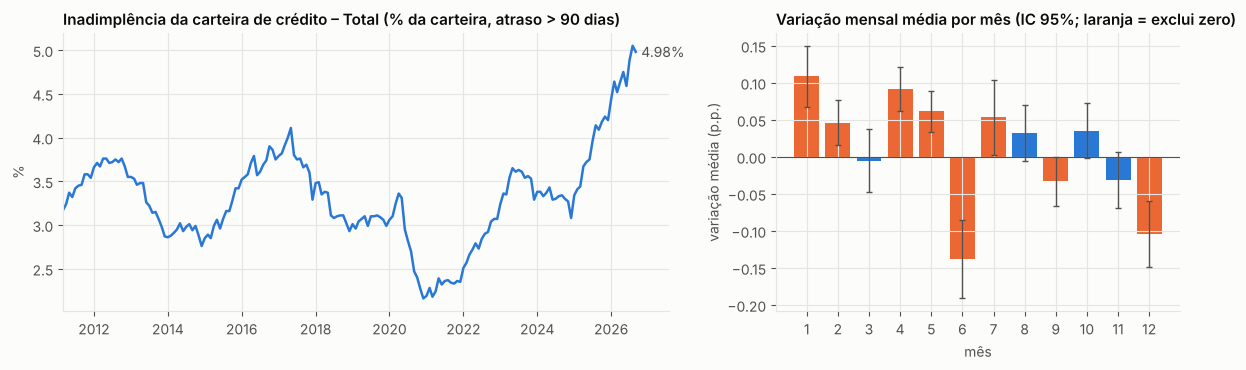

In [2]:
y = load_series(ROOT / "data" / "raw" / "bcdata.sgs.21082.csv"); dy = y.diff().dropna()
print(f"{len(y)} observações mensais: {y.index[0]:%m/%Y} a {y.index[-1]:%m/%Y} | mín {y.min():.2f}% ({y.idxmin():%m/%Y}) | máx {y.max():.2f}% ({y.idxmax():%m/%Y}) | último {y.iloc[-1]:.2f}%")

adf_l, adf_d = adfuller(y, autolag="AIC"), adfuller(dy, autolag="AIC")
print(f"ADF nível:    estatística = {adf_l[0]:.2f}, p = {adf_l[1]:.3f}   (H0: raiz unitária)")
print(f"ADF variação: estatística = {adf_d[0]:.2f}, p = {adf_d[1]:.4f}")
a = acf(dy, nlags=12)
print(f"Autocorrelação das variações mensais: lag 1 = {a[1]:.2f}, lag 2 = {a[2]:.2f}, lag 12 = {a[12]:.2f}")

# sazonalidade: a variação mensal depende do mês do ano?
m = dy.groupby(dy.index.month)
kw = stats.kruskal(*[g.values for _, g in m])
mean, se = m.mean(), m.std() / np.sqrt(m.count())
print(f"Kruskal-Wallis (variação por mês do ano): H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].plot(y.index, y.values, color=BLUE); ax[0].set_title("Inadimplência da carteira de crédito – Total (% da carteira, atraso > 90 dias)")
ax[0].annotate(f"{y.iloc[-1]:.2f}%", (y.index[-1], y.iloc[-1]), xytext=(4, 0), textcoords="offset points", color=INK2, va="center")
ax[0].set_ylabel("%"); ax[0].set_xlim(y.index[0], y.index[-1] + pd.Timedelta(days=330))
cols = [ORANGE if abs(mean[mm]) > 1.96 * se[mm] else BLUE for mm in mean.index]   # laranja: IC 95% exclui zero
ax[1].bar(mean.index, mean.values, yerr=1.96 * se.values, color=cols, error_kw={"ecolor": INK2, "lw": 1, "capsize": 2})
ax[1].axhline(0, color=INK2, lw=.8); ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel("mês"); ax[1].set_ylabel("variação média (p.p.)")
ax[1].set_title("Variação mensal média por mês (IC 95%; laranja = exclui zero)")
plt.tight_layout(); save("21_serie_sazonalidade"); plt.show()

<!--interp:sec1-->
**Leitura.**
- A inadimplência foi de 3,17% (mar/2011) a um mínimo de **2,16% (dez/2020)** e subiu a **5,05% (ago/2026)**, o máximo da amostra; o último valor é 4,98%. A série tem fases longas de queda e de alta, não oscila em torno de uma média fixa.
- **Estacionariedade:** o teste ADF não rejeita raiz unitária no nível (p = 0,66); nas variações mensais o resultado é limítrofe (p = 0,06). Por isso modelamos *variações*, não o nível.
- **Sazonalidade clara:** as variações têm autocorrelação de 0,45 na defasagem 12, e a variação média depende do mês do ano (Kruskal-Wallis p ≈ 4·10⁻¹⁴). As maiores quedas médias ocorrem em **junho (−0,14 p.p.)** e **dezembro (−0,10 p.p.)**; janeiro (+0,11) e abril (+0,09) sobem. (Os intervalos do gráfico não são corrigidos para 12 comparações; o teste de Kruskal-Wallis é o teste omnibus.) Um modelo que ignore o calendário deixa sinal na mesa — e um modelo que use "o último valor" lê essa oscilação sazonal como tendência.

## 2. O grafo de quantis da série

Cada ponto é atribuído a um quantil (nó); contamos as transições entre quantis consecutivos e normalizamos por linha para obter a matriz *P*.
Medidas de rede usadas (todas calculadas só na janela considerada):

| Medida | Significado |
|---|---|
| **self-loop** | probabilidade de permanecer no mesmo quantil (persistência) |
| **MJL** (comprimento médio de salto) | tamanho típico do salto entre quantis; pequeno = dinâmica suave/tendência |
| **entropia de transição** | quão imprevisível é o próximo quantil (1 = aleatório) |
| modularidade, caminho médio | estrutura de comunidades e distância entre nós |
| **nó atual, P(subir), P(descer)** | o que o grafo "diz" sobre o próximo passo a partir de onde a série está |

Limites dos quantis (%): [2.93 3.12 3.43 3.71] | valor médio por nó: [2.6  3.04 3.31 3.56 4.06]
self-loop = 0.80 | MJL = 0.20 nós | entropia = 0.37


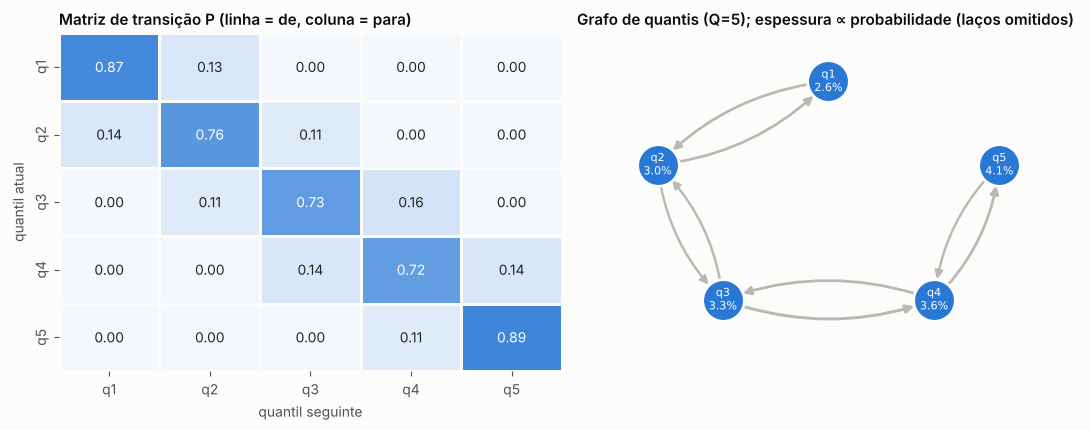

In [3]:
Q = 5
g = quantile_graph(y.values, Q)
print("Limites dos quantis (%):", np.round(g.edges, 2), "| valor médio por nó:", np.round(g.node_mean, 2))
print(f"self-loop = {self_loop_mass(g):.2f} | MJL = {mean_jump_length(g):.2f} nós | entropia = {transition_entropy(g):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(g.P, annot=True, fmt=".2f", cmap=SEQ, vmin=0, vmax=1, cbar=False, ax=ax[0], linewidths=2, linecolor=SURF,
            xticklabels=[f"q{i+1}" for i in range(Q)], yticklabels=[f"q{i+1}" for i in range(Q)])
ax[0].grid(False); ax[0].set_title("Matriz de transição P (linha = de, coluna = para)"); ax[0].set_xlabel("quantil seguinte"); ax[0].set_ylabel("quantil atual")
G = nx.DiGraph(); pos = {i: (np.cos(2*np.pi*i/Q + np.pi/2), np.sin(2*np.pi*i/Q + np.pi/2)) for i in range(Q)}
for i in range(Q):
    for j in range(Q):
        if g.P[i, j] > 0.04 and i != j: G.add_edge(i, j, w=g.P[i, j])
nx.draw_networkx_nodes(G, pos, node_color=BLUE, node_size=900, ax=ax[1], edgecolors=SURF, linewidths=2)
nx.draw_networkx_labels(G, pos, {i: f"q{i+1}\n{g.node_mean[i]:.1f}%" for i in range(Q)}, font_color="white", font_size=8, ax=ax[1])
nx.draw_networkx_edges(G, pos, width=[1 + 7 * G[u][v]["w"] for u, v in G.edges], edge_color=MUTED, arrows=True, arrowsize=12,
                       connectionstyle="arc3,rad=0.18", node_size=900, ax=ax[1])
ax[1].set_title(f"Grafo de quantis (Q={Q}); espessura ∝ probabilidade (laços omitidos)"); ax[1].axis("off"); ax[1].set_xlim(-1.4, 1.4); ax[1].set_ylim(-1.4, 1.4)
plt.tight_layout(); save("22_grafo_quantis"); plt.show()

<!--interp:sec2a-->
**Leitura.** O grafo de quantis da série inteira (Q = 5) tem **self-loop de 0,80**, comprimento médio de salto de 0,20 nós e entropia de 0,37: o próximo mês quase sempre cai no mesmo quantil ou num vizinho. A matriz *P* é praticamente **tridiagonal** (nenhum salto de mais de um quantil), e o grafo é uma cadeia q1–q2–q3–q4–q5. É a assinatura de uma série suave e persistente, que muda de nível aos poucos — o oposto de um grafo aleatório, em que todas as transições seriam equiprováveis (entropia perto de 1).

### 2.1 O grafo é diferente de ruído? Teste com surrogates

Um QG é apenas descritivo se uma série embaralhada ou sem estrutura não linear produzir o mesmo grafo. Comparamos o QG observado (Q=5) com 1.000 *surrogates* de dois tipos:
**embaralhamento** (destrói toda a dependência temporal) e **aleatorização de fase** (preserva a autocorrelação linear e destrói a não linear). *p* empírico bicaudal = (1 + nº de surrogates tão extremos) / (1 + B).

,série,surrogate,medida,observado,surrogate_média,p_empírico
0,nível,embaralhado,self-loop,0.796,0.195,0.001
1,nível,embaralhado,MJL,0.204,1.627,0.001
2,nível,embaralhado,entropia,0.370,0.972,0.001
3,nível,fase,self-loop,0.796,0.664,0.001
4,nível,fase,MJL,0.204,0.352,0.002
5,nível,fase,entropia,0.370,0.499,0.001
6,variação mensal,embaralhado,self-loop,0.222,0.195,0.385
7,variação mensal,embaralhado,MJL,1.481,1.605,0.121
8,variação mensal,embaralhado,entropia,0.973,0.972,0.918
9,variação mensal,fase,self-loop,0.222,0.196,0.386


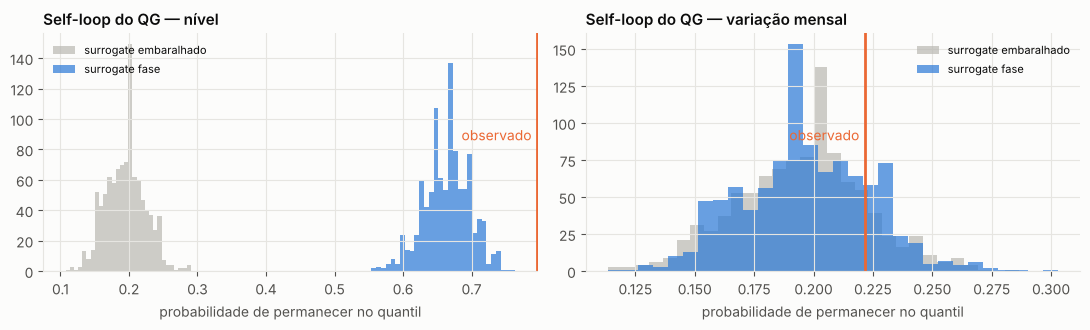

In [4]:
B = 1000
metrics = {"self-loop": self_loop_mass, "MJL": mean_jump_length, "entropia": transition_entropy}
rows, store = [], {}
for sname, s in (("nível", y.values), ("variação mensal", dy.values)):
    obs = {k: f(quantile_graph(s, Q)) for k, f in metrics.items()}
    for kind, fn in (("embaralhado", shuffle_surrogate), ("fase", phase_surrogate)):
        sur = {k: [] for k in metrics}
        for _ in range(B):
            gs = quantile_graph(fn(s, rng), Q)
            for k, f in metrics.items(): sur[k].append(f(gs))
        for k in metrics:
            v = np.array(sur[k]); p = (1 + np.sum(np.abs(v - v.mean()) >= abs(obs[k] - v.mean()))) / (1 + B)
            rows.append(dict(série=sname, surrogate=kind, medida=k, observado=obs[k], surrogate_média=v.mean(), p_empírico=p))
            store[(sname, kind, k)] = (obs[k], v)
sur_tab = pd.DataFrame(rows); display(sur_tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for a_, sname in zip(ax, ("nível", "variação mensal")):
    for kind, col in (("embaralhado", MUTED), ("fase", BLUE)):
        o, v = store[(sname, kind, "self-loop")]; a_.hist(v, bins=30, color=col, alpha=.7, label=f"surrogate {kind}")
    a_.axvline(o, color=ORANGE, lw=2); a_.annotate("observado", (o, a_.get_ylim()[1]*0.55), color=ORANGE, ha="right", xytext=(-4, 0), textcoords="offset points")
    a_.set_title(f"Self-loop do QG — {sname}"); a_.set_xlabel("probabilidade de permanecer no quantil"); a_.legend(fontsize=8, loc="upper right" if sname != "nível" else "upper left")
plt.tight_layout(); save("23_surrogates"); plt.show()

<!--interp:sec2b-->
**Leitura.**
- **Nível:** self-loop observado = 0,80, contra 0,20 nos surrogates embaralhados e 0,66 nos de fase (p ≈ 0,001 em ambos). O QG do nível é muito mais persistente que ruído (esperado) e **também que um processo linear com o mesmo espectro**. *Cuidado:* a aleatorização de fase assume estacionariedade, e o ADF sugere que o nível não é estacionário; parte dessa diferença pode ser não estacionariedade, e não "não linearidade" em sentido estrito.
- **Variação mensal:** o QG é **indistinguível de ruído** no self-loop (p = 0,39), na entropia (p = 0,92 e 0,61) e no MJL embaralhado (p = 0,12). O único p < 0,05 (MJL com surrogate de fase, p = 0,044) é um entre 12 testes sem correção, e não o tratamos como evidência.
- **Implicação para a previsão:** depois de diferenciar, o grafo de quantis não enxerga estrutura de transição além da autocorrelação linear (aqui, em grande parte, a sazonalidade). Isso antecipa o resultado da seção 3.

### 2.2 Expoente de Hurst via QG (descritivo)

Campanharo & Ramos (2016) propõem estimar o expoente de Hurst *H* pelo escalonamento do comprimento médio de salto do QG com a defasagem temporal. Implementamos essa ideia (nós definidos na série inteira; transições entre *t* e *t+τ*, τ = 1…8; Q = 10)
e **calibramos por simulação**: em *fBm* com 187 pontos o estimador é enviesado para H alto (ver `tests/`). Assim, o valor observado é mapeado para o intervalo de *H* verdadeiros compatíveis.

H_QG observado (nível, Q=10) = 0.69  |  H calibrado ≈ 0.81  |  valores de H compatíveis (faixa 5–95% simulada): 0.65 a 0.95


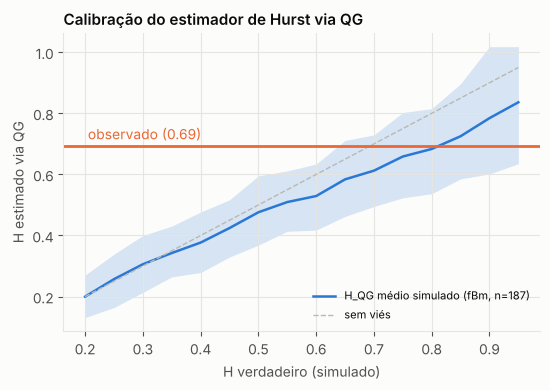

In [5]:
H_obs, lags, mjl_obs = hurst_qg(y.values, Q=10)
grid = np.round(np.arange(0.2, 0.96, 0.05), 2); sims = {}
for H in grid:
    k = np.arange(187); gam = 0.5 * (np.abs(k + 1) ** (2*H) - 2 * np.abs(k) ** (2*H) + np.abs(k - 1) ** (2*H))
    L = np.linalg.cholesky(gam[np.abs(k[:, None] - k[None, :])] + 1e-10 * np.eye(187))
    sims[H] = np.array([hurst_qg(np.cumsum(L @ rng.standard_normal(187)), Q=10)[0] for _ in range(150)])
lo90 = np.array([np.percentile(sims[h], 5) for h in grid]); hi90 = np.array([np.percentile(sims[h], 95) for h in grid]); mu = np.array([sims[h].mean() for h in grid])
compat = grid[(lo90 <= H_obs) & (H_obs <= hi90)]
H_cal = float(np.interp(H_obs, mu, grid)) if mu[0] < mu[-1] else np.nan
print(f"H_QG observado (nível, Q=10) = {H_obs:.2f}  |  H calibrado ≈ {H_cal:.2f}  |  valores de H compatíveis (faixa 5–95% simulada): {compat.min():.2f} a {compat.max():.2f}")

fig, ax = plt.subplots(figsize=(5.6, 4)); ax.fill_between(grid, lo90, hi90, color=BLUE, alpha=.18, lw=0); ax.plot(grid, mu, color=BLUE, label="H_QG médio simulado (fBm, n=187)")
ax.plot([0.2, 0.95], [0.2, 0.95], color=MUTED, ls="--", lw=1, label="sem viés"); ax.axhline(H_obs, color=ORANGE, lw=2); ax.annotate(f"observado ({H_obs:.2f})", (0.2, H_obs), xytext=(2, 5), textcoords="offset points", color=ORANGE)
ax.set_xlabel("H verdadeiro (simulado)"); ax.set_ylabel("H estimado via QG"); ax.set_title("Calibração do estimador de Hurst via QG"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); save("24_hurst_calibracao"); plt.show()

<!--interp:sec2c-->
**Leitura.** O estimador via QG dá H = **0,69** no nível; calibrado por simulação (fBm com 187 pontos, que o subestima quando H é alto) corresponde a H ≈ **0,81**, e os valores compatíveis vão de **0,65 a 0,95**. Ou seja, a série é **persistente** (H bem acima de 0,5), coerente com o ADF e com o self-loop alto, mas o intervalo é largo. Uma taxa de inadimplência é limitada e tem regimes; o modelo fBm é só uma referência, então H é um resumo descritivo, não um parâmetro estrutural.

### 2.3 Dinâmica ao longo do tempo: QG em janelas deslizantes (48 meses, Q = 4)

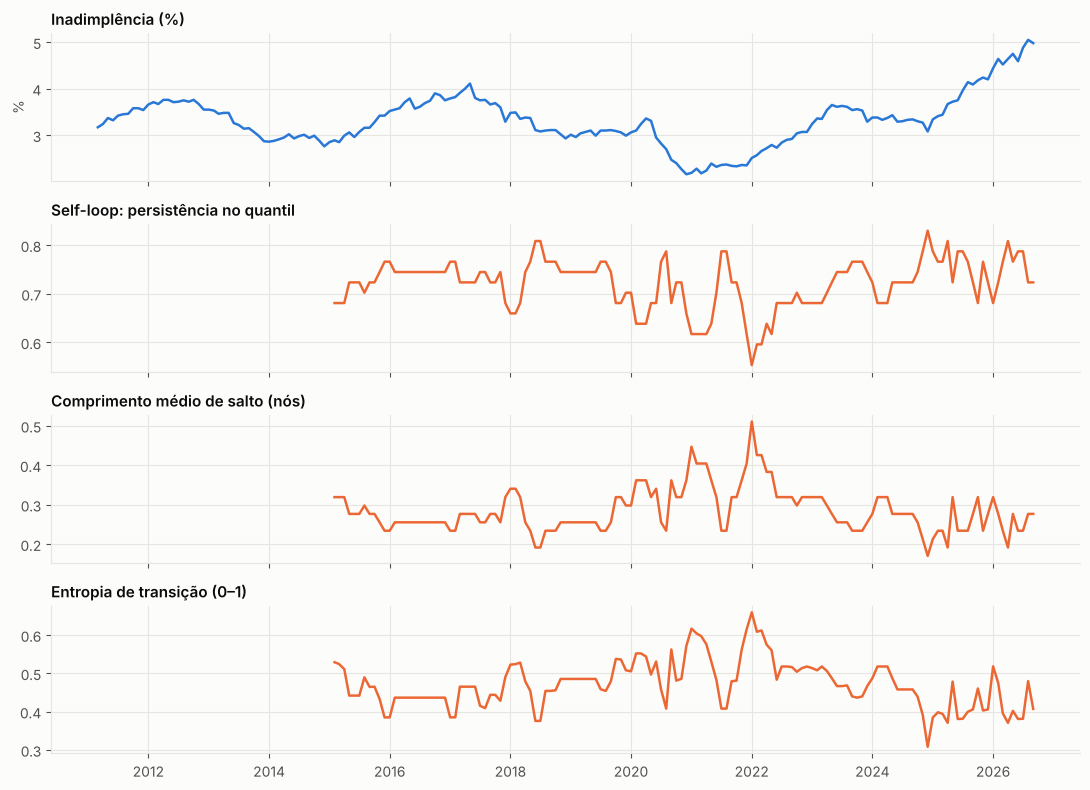

Correlação de Spearman entre a métrica do QG (janela de 48m) e |variação em 12 meses|:
{'self_loop': (np.float64(0.02), 'p=0.790'), 'mjl': (np.float64(0.01), 'p=0.882'), 'entropy': (np.float64(-0.08), 'p=0.375'), 'modularity': (np.float64(-0.3), 'p=0.001'), 'path_len': (np.float64(0.01), 'p=0.952')}
Atenção: janelas sobrepostas -> observações dependentes; os p-valores acima são otimistas.


In [6]:
W, Q4 = 48, 4
F_roll = make_features(y, W, Q4, h=1)
trend12 = y.diff(12).reindex(F_roll["date"]).values     # variação em 12 meses (contexto)
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
ax[0].plot(y.index, y.values, color=BLUE); ax[0].set_title("Inadimplência (%)"); ax[0].set_ylabel("%")
for a_, (c, t) in zip(ax[1:], (("self_loop", "Self-loop: persistência no quantil"), ("mjl", "Comprimento médio de salto (nós)"), ("entropy", "Entropia de transição (0–1)"))):
    a_.plot(F_roll["date"], F_roll[c], color=ORANGE); a_.set_title(t)
plt.tight_layout(); save("25_qg_janelas"); plt.show()
rho = {c: stats.spearmanr(F_roll[c].values[12:], np.abs(trend12[12:]), nan_policy="omit") for c in ("self_loop", "mjl", "entropy", "modularity", "path_len")}
print("Correlação de Spearman entre a métrica do QG (janela de 48m) e |variação em 12 meses|:")
print({k: (round(v.statistic, 2), f"p={v.pvalue:.3f}") for k, v in rho.items()})
print("Atenção: janelas sobrepostas -> observações dependentes; os p-valores acima são otimistas.")

<!--interp:sec2d-->
**Leitura.** As métricas do QG variam ao longo do tempo (gráfico), mas, das cinco, só a **modularidade** se associa à magnitude da variação em 12 meses (Spearman −0,30; self-loop, MJL, entropia e caminho médio ficam em torno de zero). Esse p = 0,001 é otimista: as janelas de 48 meses se sobrepõem quase totalmente (observações muito dependentes) e não há correção para as 5 métricas olhadas. Trate como **exploratório**. A pergunta relevante, se essas métricas ajudam a *prever*, é testada diretamente na seção 3.

## 3. Previsão walk-forward com e sem features do grafo

**Alvo:** *y(t+h) − y(t)*, h = 1, 3, 6 meses. **Avaliação:** a cada mês de fev/2019 a set/2026 os modelos são reestimados só com alvos já observados (para h > 1 descarta-se o que ainda não se realizou) e fazem uma previsão.
**Features:** *base* = variações recentes (1, 2, 3 e 12 meses) e posição na janela; *sazonal* = harmônicos do mês-alvo; *QG* = as 10 medidas do grafo da janela de 48 meses (Q=4).
**Modelos:** Ridge (penalização escolhida por validação cruzada) e Random Forest raso. O **QG-Markov** usa o próprio grafo como previsor (mapa inverso aproximado): valor esperado do próximo quantil, dado o nó atual.

In [7]:
T0 = 95                                               # primeira previsão: fev/2019 (mínimo de 36 linhas de treino)
HS = (1, 3, 6); feats, res, arima = {}, {}, {}
t0 = time.time()
for h in HS:
    feats[h] = make_features(y, 48, 4, h=h); res[h] = walk_forward(feats[h], T0, h=h)
    arima[h] = arima_walk_forward(y, res[h].index.min(), res[h].index.max(), (1, 1, 1), h=h).reindex(res[h].index)
    print(f"h={h}: {len(res[h])} previsões ({res[h].date.min():%m/%Y}–{res[h].date.max():%m/%Y}) | {time.time()-t0:.0f}s")
tabs = {}
for h in HS:
    tabs[h] = score_table(res[h], extra={"ARIMA(1,1,1)": arima[h].values})
print("\nh = 1 mês à frente"); display(tabs[1].round(3))

h=1: 91 previsões (02/2019–08/2026) | 66s


h=3: 89 previsões (02/2019–06/2026) | 131s


h=6: 86 previsões (02/2019–03/2026) | 195s

h = 1 mês à frente


,RMSE,MAE,RMSE_rel_RW,acerto_direcao
modelo,,,,
Passeio aleatório (Δ=0),0.115,0.088,1.000,NaN
Drift,0.114,0.088,0.992,0.580
Sazonal (média do mês),0.094,0.076,0.820,0.773
AR + sazonal (Ridge),0.104,0.079,0.905,0.659
QG-Markov (direto),0.308,0.232,2.679,0.466
QG-Markov nó→nó (pós-hoc),0.133,0.103,1.160,0.455
QG apenas (Ridge),0.118,0.090,1.024,0.557
AR + sazonal + QG (Ridge),0.113,0.086,0.987,0.602
AR + sazonal (RF),0.092,0.072,0.798,0.739


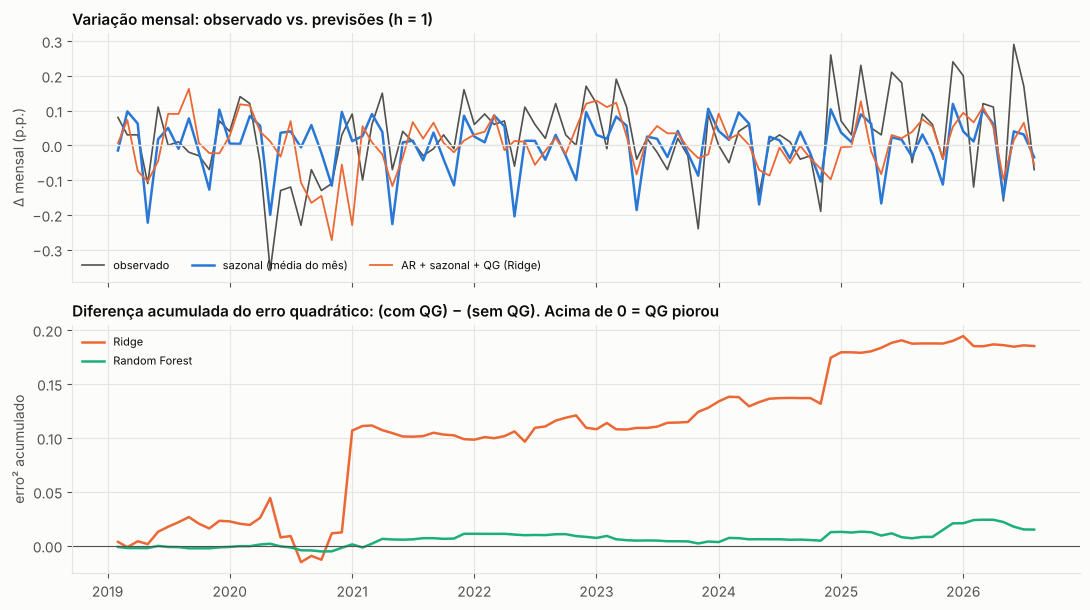

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
R = res[1]; d = R["date"]
ax[0].plot(d, R["actual"], color=INK2, lw=1.2, label="observado"); ax[0].plot(d, R["Sazonal (média do mês)"], color=BLUE, label="sazonal (média do mês)")
ax[0].plot(d, R["AR + sazonal + QG (Ridge)"], color=ORANGE, lw=1.3, label="AR + sazonal + QG (Ridge)")
ax[0].axhline(0, color=GRID, lw=1); ax[0].set_ylabel("Δ mensal (p.p.)"); ax[0].set_title("Variação mensal: observado vs. previsões (h = 1)"); ax[0].legend(ncol=3, fontsize=8, loc="lower left")
e = lambda c: R["actual"].values - R[c].values
for base, aug, col, lab in (("AR + sazonal (Ridge)", "AR + sazonal + QG (Ridge)", ORANGE, "Ridge"), ("AR + sazonal (RF)", "AR + sazonal + QG (RF)", AQUA, "Random Forest")):
    ax[1].plot(d, np.cumsum(e(aug) ** 2 - e(base) ** 2), color=col, label=lab)
ax[1].axhline(0, color=INK2, lw=.8); ax[1].set_title("Diferença acumulada do erro quadrático: (com QG) − (sem QG). Acima de 0 = QG piorou")
ax[1].set_ylabel("erro² acumulado"); ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); save("26_previsao_h1"); plt.show()

<!--interp:sec3a-->
**Leitura (h = 1 mês).**
- A previsão sazonal simples (variação média do mês) tem RMSE de 0,094 p.p., **18% menor que o passeio aleatório** (0,115). O melhor modelo é o Random Forest sem QG (0,092). O ARIMA(1,1,1) fica igual ao passeio aleatório (0,996).
- **Com QG, os modelos ficam iguais ou piores:** Ridge 0,113 vs 0,104 sem QG; Random Forest 0,093 vs 0,092. No gráfico inferior, a diferença acumulada do erro do Ridge sobe em **saltos concentrados em poucos meses** (final de 2020 e início de 2025, rupturas de regime), e não de forma gradual: é onde as features calculadas na janela de 48 meses extrapolam errado.
- Usar o QG diretamente como previsor (Markov) é muito pior (2,7× o erro do passeio aleatório): ver seção 3.4.

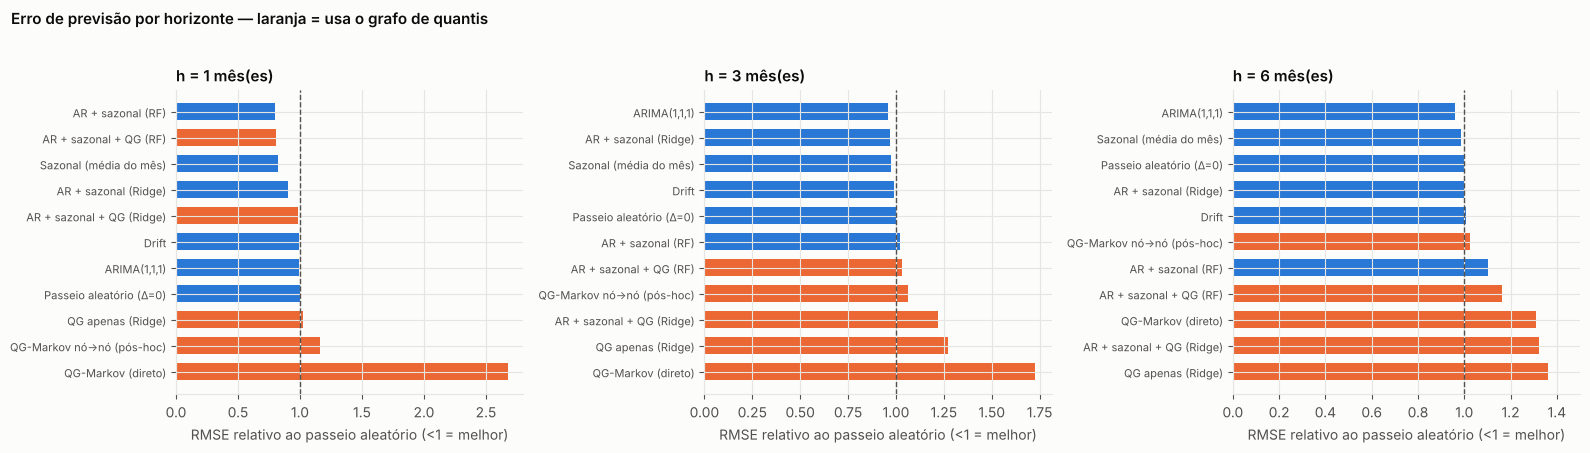


h = 3 meses à frente


,RMSE,MAE,RMSE_rel_RW,acerto_direcao
modelo,,,,
Passeio aleatório (Δ=0),0.224,0.178,1.000,NaN
Drift,0.222,0.177,0.992,0.506
Sazonal (média do mês),0.218,0.177,0.973,0.575
AR + sazonal (Ridge),0.217,0.166,0.966,0.609
QG-Markov (direto),0.387,0.299,1.726,0.506
QG-Markov nó→nó (pós-hoc),0.239,0.189,1.065,0.425
QG apenas (Ridge),0.285,0.224,1.270,0.460
AR + sazonal + QG (Ridge),0.273,0.209,1.219,0.460
AR + sazonal (RF),0.229,0.183,1.021,0.529



h = 6 meses à frente


,RMSE,MAE,RMSE_rel_RW,acerto_direcao
modelo,,,,
Passeio aleatório (Δ=0),0.381,0.306,1.000,NaN
Drift,0.384,0.314,1.007,0.434
Sazonal (média do mês),0.375,0.309,0.984,0.482
AR + sazonal (Ridge),0.381,0.306,1.001,0.602
QG-Markov (direto),0.499,0.400,1.311,0.458
QG-Markov nó→nó (pós-hoc),0.391,0.306,1.025,0.470
QG apenas (Ridge),0.519,0.421,1.363,0.410
AR + sazonal + QG (Ridge),0.503,0.400,1.322,0.458
AR + sazonal (RF),0.421,0.342,1.104,0.458


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), sharex=False)
for a_, h in zip(ax, HS):
    t = tabs[h].sort_values("RMSE_rel_RW")
    cols = [ORANGE if "QG" in n else BLUE for n in t.index]
    a_.barh(t.index, t["RMSE_rel_RW"], color=cols, height=.65); a_.axvline(1, color=INK2, lw=1, ls="--")
    a_.set_title(f"h = {h} mês(es)"); a_.invert_yaxis(); a_.set_xlabel("RMSE relativo ao passeio aleatório (<1 = melhor)")
    a_.tick_params(axis='y', labelsize=8)
    a_.set_xlim(0, max(1.5, min(2.8, t["RMSE_rel_RW"].max() * 1.05)))
fig.suptitle("Erro de previsão por horizonte — laranja = usa o grafo de quantis", x=0.01, ha="left", y=1.02, fontsize=11, fontweight="semibold")
plt.tight_layout(); save("27_rmse_relativo"); plt.show()
for h in (3, 6): print(f"\nh = {h} meses à frente"); display(tabs[h].round(3))

<!--interp:sec3b-->
**Leitura (h = 3 e 6 meses).**
- Em 3 meses, os melhores modelos (ARIMA 0,958; AR+sazonal Ridge 0,966; sazonal 0,973) ficam a **3–4% do passeio aleatório**; em 6 meses, só o ARIMA (0,961) se afasta um pouco de 1. Com horizonte maior, quase não há previsibilidade acima de "fica onde está".
- Todo modelo com QG fica **pior que o passeio aleatório** nesses horizontes (Ridge com QG: 1,22 em h=3 e 1,32 em h=6; RF com QG: 1,03 e 1,17). Mais variáveis correlacionadas e poucas linhas de treino (de 36 a 139) é receita para variância.
- O acerto de direção em 3 e 6 meses fica **abaixo da taxa-base** (ver seção 3.1): o período de teste tem uma alta sustentada e um modelo sazonal, sem tendência, erra o sentido sistematicamente.

### 3.1 Testes estatísticos (família pré-especificada)

**Família A (pergunta principal):** *AR + sazonal + QG* vs. *AR + sazonal*, para Ridge e Random Forest, h = 1, 3, 6 → 6 testes, p-valores corrigidos por **Holm**.
Razão de RMSE < 1 favorece o QG. IC 95% por bootstrap em blocos móveis. **Família B:** os modelos de referência (sazonal e ARIMA) vencem o passeio aleatório? (6 testes, Holm). Também comparamos o acerto de direção com a taxa-base.

In [10]:
famA = []
for h in HS:
    R = res[h]; a = R["actual"].values
    for kind, base, aug in (("Ridge", "AR + sazonal (Ridge)", "AR + sazonal + QG (Ridge)"), ("Random Forest", "AR + sazonal (RF)", "AR + sazonal + QG (RF)")):
        ea, eb = a - R[aug].values, a - R[base].values
        dm, p = diebold_mariano(ea, eb, h=h); r, lo, hi = block_bootstrap_ratio(ea, eb, block=max(6, 2 * h))
        famA.append(dict(horizonte=h, modelo=kind, RMSE_com_QG=rmse(ea), RMSE_sem_QG=rmse(eb), razão=r, IC95_inf=lo, IC95_sup=hi, DM=dm, p=p))
famA = pd.DataFrame(famA); famA["p_Holm"] = holm(famA["p"].values); display(famA.round(3))

famB = []
for h in HS:
    R = res[h]; a = R["actual"].values
    for nome, pred in (("Sazonal (média do mês)", R["Sazonal (média do mês)"].values), ("ARIMA(1,1,1)", arima[h].values)):
        es, ez = a - pred, a
        dm, p = diebold_mariano(es, ez, h=h); r, lo, hi = block_bootstrap_ratio(es, ez, block=max(6, 2 * h))
        famB.append(dict(horizonte=h, modelo=nome, RMSE_modelo=rmse(es), RMSE_passeio=rmse(ez), razão=r, IC95_inf=lo, IC95_sup=hi, DM=dm, p=p))
famB = pd.DataFrame(famB); famB["p_Holm"] = holm(famB["p"].values); display(famB.round(3))

print("Acerto de direção vs. taxa-base (proporção da classe majoritária de meses de alta/queda), teste binomial unilateral:")
for h in HS:
    a = res[h]["actual"].values; nz = a != 0; up = (a[nz] > 0).mean(); major = max(up, 1 - up)
    for nome in ("Sazonal (média do mês)", "AR + sazonal (Ridge)"):
        hit = np.sign(res[h][nome].values[nz]) == np.sign(a[nz]); bt = stats.binomtest(int(hit.sum()), int(nz.sum()), major, alternative="greater")
        print(f"  h={h} {nome:24s}: acerto {hit.mean():.1%} vs base {major:.1%} (n={nz.sum()}), p = {bt.pvalue:.4f}")

,horizonte,modelo,RMSE_com_QG,RMSE_sem_QG,razão,IC95_inf,IC95_sup,DM,p,p_Holm
0,1,Ridge,0.113,0.104,1.090,0.997,1.233,1.513,0.134,0.535
1,1,Random Forest,0.093,0.092,1.010,0.990,1.044,0.775,0.440,1.000
2,3,Ridge,0.273,0.217,1.261,1.078,1.616,2.064,0.042,0.210
3,3,Random Forest,0.231,0.229,1.008,0.972,1.110,0.214,0.831,1.000
4,6,Ridge,0.503,0.381,1.321,1.097,1.629,2.280,0.025,0.151
5,6,Random Forest,0.444,0.421,1.055,0.970,1.273,0.889,0.376,1.000


,horizonte,modelo,RMSE_modelo,RMSE_passeio,razão,IC95_inf,IC95_sup,DM,p,p_Holm
0,1,Sazonal (média do mês),0.094,0.115,0.820,0.736,0.918,-2.528,0.013,0.079
1,1,"ARIMA(1,1,1)",0.114,0.115,0.996,0.959,1.033,-0.185,0.853,1.000
2,3,Sazonal (média do mês),0.218,0.224,0.973,0.873,1.093,-0.441,0.661,1.000
3,3,"ARIMA(1,1,1)",0.215,0.224,0.958,0.901,1.003,-1.688,0.095,0.474
4,6,Sazonal (média do mês),0.375,0.381,0.984,0.951,1.069,-0.419,0.676,1.000
5,6,"ARIMA(1,1,1)",0.366,0.381,0.961,0.921,1.037,-0.872,0.386,1.000


Acerto de direção vs. taxa-base (proporção da classe majoritária de meses de alta/queda), teste binomial unilateral:
  h=1 Sazonal (média do mês)  : acerto 77.3% vs base 61.4% (n=88), p = 0.0011
  h=1 AR + sazonal (Ridge)    : acerto 65.9% vs base 61.4% (n=88), p = 0.2229
  h=3 Sazonal (média do mês)  : acerto 57.5% vs base 66.7% (n=87), p = 0.9716
  h=3 AR + sazonal (Ridge)    : acerto 60.9% vs base 66.7% (n=87), p = 0.8934
  h=6 Sazonal (média do mês)  : acerto 48.2% vs base 68.7% (n=83), p = 1.0000
  h=6 AR + sazonal (Ridge)    : acerto 60.2% vs base 68.7% (n=83), p = 0.9598


<!--interp:sec31-->
**Leitura.**
- **Família A (o QG ajuda?):** **nenhuma** das 6 comparações favorece o QG; todas as razões de RMSE são maiores que 1 (de 1,008 a 1,32). No Ridge, a piora em h = 3 (razão 1,26; IC 95% 1,08–1,62) e h = 6 (1,32; IC 1,10–1,63) tem IC de bootstrap que exclui 1 e p bruto de 0,042 e 0,025, mas **depois de Holm os p-valores sobem para 0,21 e 0,15**, então não é significativo. Para o Random Forest, os ICs incluem 1. Conclusão: **sem evidência de que o QG melhora a previsão; indício (não conclusivo) de que piora no Ridge em horizontes longos.**
- **Família B (referências vs. passeio aleatório):** o modelo sazonal em h = 1 tem razão de RMSE 0,82 (IC 95% 0,74–0,92) e p bruto = 0,013, mas **p ajustado por Holm = 0,079**: com 6 testes, não é significativo a 5%, embora seja o efeito mais forte do estudo. ARIMA vs. passeio: h = 3, razão 0,958 (p bruto 0,095); h = 6, razão 0,961 (p = 0,39); nenhum significativo.
- **Direção (fora da família, teste único):** em h = 1 o modelo sazonal acerta o sentido da variação em **77,3% dos meses contra 61,4% da taxa-base** (binomial, p = 0,001), apoiando o sinal sazonal. Em h = 3 e 6 não supera a taxa-base.

### 3.2 Robustez: janela, número de quantis e QG sobre as variações

A conclusão depende de escolhas arbitrárias (janela, Q)? Para cada combinação, comparamos Ridge *com* vs. *sem* features do QG (razão de RMSE; > 1 = QG piora), mesmo período de teste.
Última linha: QG construído sobre as **variações mensais** em vez do nível.

30s


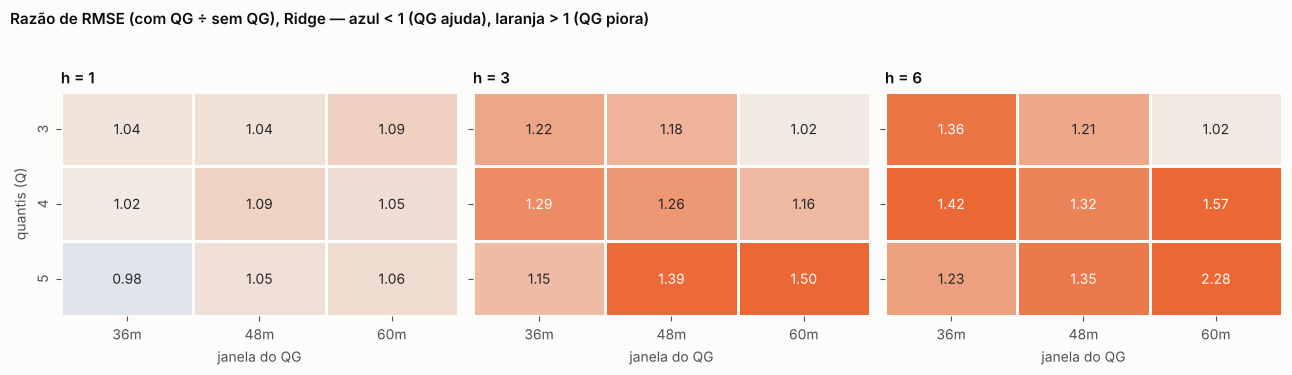

QG sobre as variações mensais (janela 48, Q=4): {1: 1.072, 3: 1.136, 6: 1.151}
Razão mínima / mediana / máxima em toda a grade: 0.98 / 1.16 / 2.28  (n = 30)


In [11]:
mods = {"base": MODELS["AR + sazonal (Ridge)"], "aug": MODELS["AR + sazonal + QG (Ridge)"]}
grid_rows = []; t0 = time.time()
for h in HS:
    for win in (36, 48, 60):
        for Qq in (3, 4, 5):
            F = make_features(y, win, Qq, h=h); R = walk_forward(F, T0, models=mods, h=h); a = R["actual"].values
            grid_rows.append(dict(h=h, janela=win, Q=Qq, razão=rmse(a - R["aug"].values) / rmse(a - R["base"].values)))
    F = make_features(y, 48, 4, h=h, qg_on="diff"); R = walk_forward(F, T0, models=mods, h=h); a = R["actual"].values
    grid_rows.append(dict(h=h, janela="48 (QG nas variações)", Q=4, razão=rmse(a - R["aug"].values) / rmse(a - R["base"].values)))
print(f"{time.time()-t0:.0f}s"); gr = pd.DataFrame(grid_rows)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a_, h in zip(ax, HS):
    pv = gr[(gr.h == h) & (gr.janela.astype(str).isin(["36", "48", "60"]))].pivot(index="Q", columns="janela", values="razão")
    pv.columns = [f"{int(c)}m" for c in pv.columns]
    sns.heatmap(pv, annot=True, fmt=".2f", cmap=DIV, norm=mcolors.TwoSlopeNorm(1, 0.8, 1.4), cbar=False, ax=a_, linewidths=2, linecolor=SURF)
    a_.grid(False); a_.set_title(f"h = {h}"); a_.set_xlabel("janela do QG"); a_.set_ylabel("quantis (Q)" if h == 1 else "")
fig.suptitle("Razão de RMSE (com QG ÷ sem QG), Ridge — azul < 1 (QG ajuda), laranja > 1 (QG piora)", x=0.01, ha="left", y=1.03, fontsize=11, fontweight="semibold")
plt.tight_layout(); save("28_robustez"); plt.show()
print("QG sobre as variações mensais (janela 48, Q=4):", gr[gr.janela == "48 (QG nas variações)"].set_index("h")["razão"].round(3).to_dict())
print(f"Razão mínima / mediana / máxima em toda a grade: {gr.razão.min():.2f} / {gr.razão.median():.2f} / {gr.razão.max():.2f}  (n = {len(gr)})")

<!--interp:sec32-->
**Leitura.** A conclusão não é um acidente da janela ou de Q: nas **30 configurações** (3 horizontes × 3 janelas × 3 valores de Q, mais a variante com QG sobre as variações), a razão de RMSE (com QG ÷ sem QG) tem **mediana 1,16, mínimo 0,98 e máximo 2,28**. A única configuração em que o QG ajuda tem ganho de 2%, dentro do ruído, e é a favorita entre 30 tentativas. Construir o QG sobre as variações mensais também piora (1,07, 1,14 e 1,15 nos três horizontes).

### 3.3 O que o modelo com QG de fato usou? (coeficientes padronizados do Ridge, h = 1)

Penalização escolhida (alpha) = 37.28


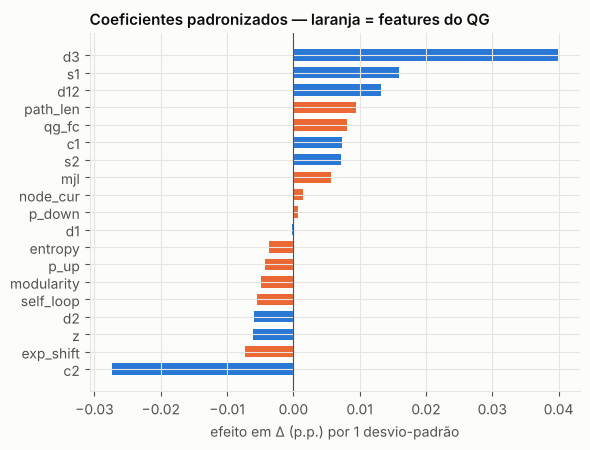

In [12]:
lab = feats[1][feats[1]["target"].notna()]; cols = BASE_COLS + SEAS_COLS + QG_COLS
mdl = _ridge().fit(lab[cols].values, lab["target"].values); coef = pd.Series(mdl[-1].coef_, index=cols).sort_values()
print(f"Penalização escolhida (alpha) = {mdl[-1].alpha_:.2f}")
fig, ax = plt.subplots(figsize=(6, 4.6)); ax.barh(coef.index, coef.values, color=[ORANGE if c in QG_COLS else BLUE for c in coef.index], height=.65)
ax.axvline(0, color=INK2, lw=.8); ax.set_title("Coeficientes padronizados — laranja = features do QG"); ax.set_xlabel("efeito em Δ (p.p.) por 1 desvio-padrão")
plt.tight_layout(); save("29_coeficientes"); plt.show()

<!--interp:sec33-->
**Leitura.** O Ridge escolhido é fortemente regularizado (α ≈ 37), e todos os coeficientes são pequenos. Os maiores são a variação de três meses atrás e os harmônicos sazonais; cada medida do QG recebe um peso minúsculo, mas **juntas somam cerca de 30% da magnitude total dos coeficientes** (0,051 de 0,174), acrescentando variância sem sinal correspondente, o que é compatível com a piora observada.

### 3.4 QG como previsor direto (mapa inverso aproximado)

A versão **pré-especificada** prevê o salto até o valor esperado do próximo nó *a partir do valor atual*. Ela foi muito pior que o passeio aleatório (tabelas acima). Diagnóstico: com Q = 4 o grafo só conhece a faixa, e o erro de posição dentro da faixa entra inteiro na previsão.
Por isso foi acrescentada, **depois de ver esse resultado (pós-hoc)**, a variante "nó→nó" (salto esperado entre *médias* de nós). Ambas aparecem nas tabelas; a pós-hoc não deve ser lida como confirmatória.

In [13]:
cmp = pd.DataFrame({h: tabs[h].loc[["Passeio aleatório (Δ=0)", "QG-Markov (direto)", "QG-Markov nó→nó (pós-hoc)"], "RMSE_rel_RW"] for h in HS}).round(3)
cmp.columns = [f"h={h}" for h in HS]; display(cmp)

,h=1,h=3,h=6
modelo,,,
Passeio aleatório (Δ=0),1.000,1.000,1.000
QG-Markov (direto),2.679,1.726,1.311
QG-Markov nó→nó (pós-hoc),1.160,1.065,1.025


<!--interp:sec34-->
**Leitura.** Como previsor direto, o QG-Markov **pré-especificado** tem erro 2,7×, 1,7× e 1,3× o do passeio aleatório (h = 1, 3, 6). A variante **nó→nó (pós-hoc)** melhora (1,16; 1,07; 1,03) e se aproxima do passeio aleatório, mas **não o supera**: como a série é muito persistente, o grafo prevê quase "nenhuma mudança" e, quando prevê uma, está errado com frequência. Há também um problema de estimação: uma matriz 4×4 estimada com ~47 transições tem poucos pontos por linha (~12), então as probabilidades condicionais são ruidosas.

## 4. Previsão de referência para os próximos meses

,horizonte,alvo,modelo,previsão,intervalo_80_inf,intervalo_80_sup
0,1 mês(es),10/2026,sazonal (média do mês),5.02,4.91,5.16
1,3 mês(es),12/2026,passeio aleatório,4.98,4.76,5.29
2,6 mês(es),03/2027,passeio aleatório,4.98,4.71,5.48


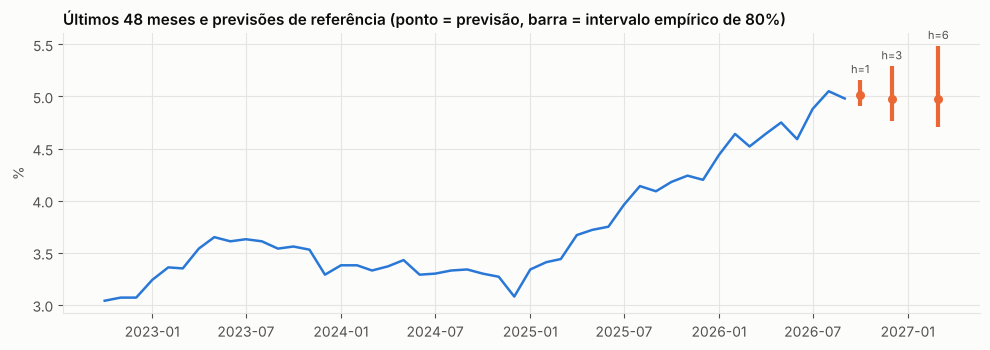

In [14]:
n = len(y); last = float(y.iloc[-1]); out = []
for h in HS:
    F = feats[h]; lab = F[F["target"].notna()]; row = F.loc[n - 1]; R = res[h]; a = R["actual"].values
    if h == 1:
        season = lab.groupby("tmonth")["target"].mean(); delta = float(season.get(int(row["tmonth"]), lab["target"].mean()))
        err = a - R["Sazonal (média do mês)"].values; nome = "sazonal (média do mês)"
    else:
        delta, err, nome = 0.0, a, "passeio aleatório"
    q10, q90 = np.percentile(err, [10, 90]); tgt = (y.index[-1] + pd.DateOffset(months=h))
    out.append(dict(horizonte=f"{h} mês(es)", alvo=f"{tgt:%m/%Y}", modelo=nome, previsão=last + delta, intervalo_80_inf=last + delta + q10, intervalo_80_sup=last + delta + q90))
fc = pd.DataFrame(out); display(fc.round(2))
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(y.index[-48:], y.values[-48:], color=BLUE)
for r, h in zip(out, HS):
    tgt = y.index[-1] + pd.DateOffset(months=h); ax.vlines(tgt, r["intervalo_80_inf"], r["intervalo_80_sup"], color=ORANGE, lw=3); ax.scatter([tgt], [r["previsão"]], color=ORANGE, zorder=3, s=30)
    ax.annotate(f"h={h}", (tgt, r["intervalo_80_sup"]), xytext=(0, 5), textcoords="offset points", ha="center", color=INK2, fontsize=8)
ax.set_title("Últimos 48 meses e previsões de referência (ponto = previsão, barra = intervalo empírico de 80%)"); ax.set_ylabel("%")
plt.tight_layout(); save("30_previsao_referencia"); plt.show()

<!--interp:sec4-->
**Leitura.** Previsões de referência a partir de set/2026 (4,98%): **out/2026 ≈ 5,02%** (intervalo de 80%: 4,91–5,16), **dez/2026 ≈ 4,98%** (4,76–5,29) e **mar/2027 ≈ 4,98%** (4,71–5,48). Em h = 1 usamos o modelo sazonal; em 3 e 6 meses, o passeio aleatório, porque nenhum modelo o supera de forma significativa. *Avisos:* os intervalos são empíricos (quantis dos erros de 2019–2026, que incluem a ruptura de 2020) e não condicionais; o ARIMA foi ligeiramente melhor em 3 e 6 meses, sem significância; e o patamar atual é o mais alto da amostra, então vale cautela ao extrapolar. Isto é uma referência estatística, não uma recomendação.

## 5. Salvando resultados

In [15]:
summary = {
  "serie": "BCB SGS 21082 - Inadimplencia da carteira de credito - Total", "n_obs": int(len(y)), "periodo": [f"{y.index[0]:%Y-%m}", f"{y.index[-1]:%Y-%m}"],
  "teste_walk_forward": {"inicio": f"{res[1].date.min():%Y-%m}", "n_previsoes": {int(h): int(len(res[h])) for h in HS}},
  "RMSE_relativo_ao_passeio_aleatorio": {int(h): tabs[h]["RMSE_rel_RW"].round(4).to_dict() for h in HS},
  "familia_A_QG_vs_sem_QG": famA.round(4).to_dict(orient="records"), "familia_B_sazonal_vs_passeio": famB.round(4).to_dict(orient="records"),
  "robustez_razao_RMSE": {"min": float(gr.razão.min()), "mediana": float(gr.razão.median()), "max": float(gr.razão.max())},
  "hurst_qg": {"observado": float(H_obs), "calibrado": None if np.isnan(H_cal) else float(H_cal)},
  "previsao_referencia": fc.round(3).to_dict(orient="records"),
}
(ROOT / "reports" / "metrics_credito.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str)); print("ok")

ok


<!--interp:conclusoes-->
## 6. Conclusões

**O que os dados mostram**
1. **O grafo de quantis descreve bem a série.** Ele captura uma dinâmica persistente (self-loop 0,80, matriz tridiagonal, H ≈ 0,8 após calibração), claramente distinta de ruído e de surrogates embaralhados. Como ferramenta de **caracterização**, o método de Campanharo et al. funciona.
2. **Mas suas features não melhoram a previsão da inadimplência.** Em nenhuma das 6 comparações pré-especificadas o QG reduz o erro; a razão mediana de RMSE é 1,16 em 30 configurações, e no Ridge a piora em horizontes longos é indicativa (IC de bootstrap exclui 1; não significativa após Holm). Depois de diferenciar, o QG é indistinguível de ruído, ou seja, não enxerga estrutura além da autocorrelação linear.
3. **O que funciona é a sazonalidade, em h = 1.** A média por mês reduz o RMSE em 18% e acerta o sentido em 77% dos meses (taxa-base de 61%). Com correção de Holm para 6 testes, a vantagem de RMSE tem p = 0,079; trate como forte indício, não como prova.
4. **Para 3 e 6 meses, nada supera "fica onde está" de forma significativa.** O ARIMA(1,1,1) fica ~4% melhor, sem significância.

**Por que o QG pode não ter ajudado aqui (hipóteses, não testadas)**
- Série **agregada, curta** (187 pontos) e muito persistente; janelas de 48 meses dão ~47 transições para estimar uma matriz 4×4.
- O QG de nível **não codifica o calendário**, e é no calendário que está o sinal previsível.
- Em séries longas e de alta frequência (EEG, sinais físicos, séries diárias), onde o método foi mostrado, há muito mais transições por janela.

**Limitações:** uma única série; 91 previsões (poder limitado); escolhas de janela e Q; período de teste com regimes incomuns (2020 e 2025–26); nenhuma variável macroeconômica; um desvio do plano (variante nó→nó), sinalizado como pós-hoc.

**Próximos passos com mais chance de acerto:** (i) acrescentar exógenas (Selic, desemprego, concessões, IPCA); (ii) aplicar o QG onde o método brilha: **séries de comportamento por cliente** (atraso, uso do limite, pagamentos), com features do grafo como entrada de um *score* de crédito individual; (iii) usar o QG para **classificar regimes** em vez de prever o próximo mês; (iv) séries de maior frequência (diárias).